In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("Ice_cream selling data.csv")

In [4]:
df.corr()

,Temperature (°C),Ice Cream Sales (units)
Temperature (°C),1.000000,-0.175184
Ice Cream Sales (units),-0.175184,1.000000


In [5]:
x=df[['Temperature (°C)']]
y=df['Ice Cream Sales (units)']

In [6]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8,random_state=42)

'''  
Syntax for linear regression
fromsklearn.linearmodel import LinearRegression

sklearn:---> package/tool
linear_model:--> module(.py file)
LinearRegression:--> class(from linear_model) module

#model creation 

model_lr=LinearRegression()


#model training

fit()

what is fit()?

---> it learns the patterns from the data(input and output)

model_lr.fit(xtrain,ytrain) # it uses OLS(ordinal least square method)

#finds the best fit line(mx+c)

--> findS slope and intercept
'''

In [7]:
model_lr=LinearRegression()

In [8]:
model_lr.fit(xtrain,ytrain) 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-1.15]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature (°C)']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [9]:
model_lr.intercept_   # returns single value

np.float64(17.139213127718417)

In [10]:
model_lr.coef_  # returns list of values

array([-1.14658686])

In [11]:
ytrain_predicted=model_lr.predict(xtrain)  

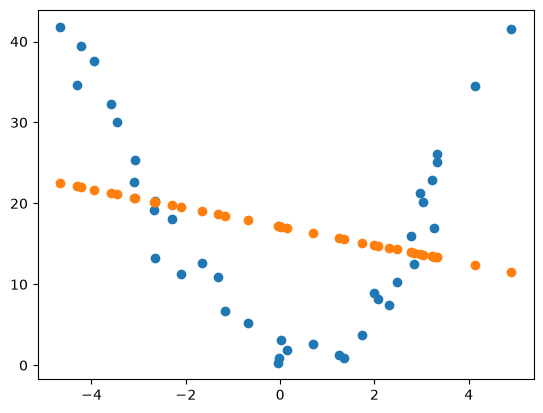

In [12]:
plt.scatter(xtrain,ytrain)   # actual input vs actual output 
plt.scatter(xtrain,ytrain_predicted) # actual input vs model predicted output

#### Conclusion:--->



Model is not able to capture the pattrens.

#### Reason    :--->

The data is non-linear and linear regression can capture only linear data.



'''
Why are we  comparing this?

1) plt.scatter(xtrain,ytrain) # actual input vs actual output 
2) plt.scatter(xtrain,ytrain_predicted) # actual input vs predicted output

Answer:--->

From this comparison between actual and predicted patterns
we can conclude how well the model captures the patterns during model training.

'''

In [13]:
ytest_predicted=model_lr.predict(xtest)

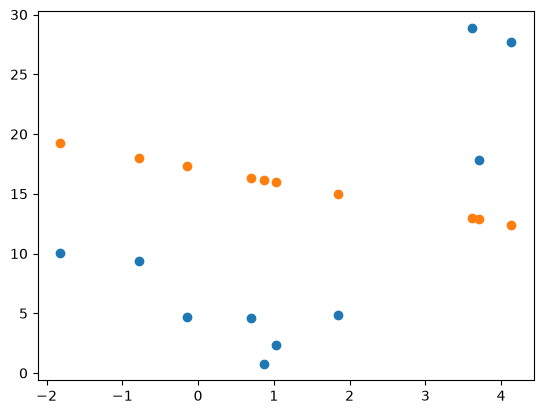

In [14]:
plt.scatter(xtest,ytest)
plt.scatter(xtest,ytest_predicted)

#### Conclusion:--->

1) plt.scatter(xtest,ytest) # actual input vs actual output 
2) plt.scatter(xtest,ytest_predicted) # actual input vs predicted output

Answer:--->

Model is not going to predict the accurate output in future.
From this comparison between actual and predicted patterns
we can conclude how well the model is going to predict output in future as model fails to capture correct val for unseen data.





#### Model Evaluation:--->

1) Error 

    Error=> Actual Output( y<sub>i</sub> ) - Predicted output( y<sub>i</sub><sup>^</sup> )

2) Train Data Error=> ytrain - ytrain_predicted(model.predict(xtrain))

3) Test Data Error=> ytest - ytest_predicted(model.predict(xtest))



In [15]:
train_data=pd.DataFrame(
    {
        'xtrain':xtrain['Temperature (°C)'],
        'ytrain':ytrain,
        'ytrain_pred':ytrain_predicted
    }
)

train_data['Error']=train_data['ytrain']-train_data['ytrain_pred']

In [16]:
train_data

,xtrain,ytrain,ytrain_pred,Error
12,-2.111870,11.218294,19.560655,-8.342361
4,-3.578554,32.284531,21.242336,11.042195
34,2.318591,7.412094,14.480747,-7.068653
8,-2.672461,19.226970,20.203422,-0.976452
3,-3.949661,37.539845,21.667843,15.872002
6,-3.108440,22.635401,20.703310,1.932092
40,3.211366,22.839406,13.457103,9.382303
41,3.270044,16.983279,13.389824,3.593455
46,4.130868,34.530743,12.402814,22.127929
15,-1.326379,10.957731,18.660022,-7.702291


In [17]:
from sklearn.metrics import mean_squared_error

train_mse=mean_squared_error(ytrain,ytrain_predicted)
test_mean=mean_squared_error(ytest,ytest_predicted)

print(train_mse,test_mean)



143.33160093981343 149.32629119325185


In [ ]:
ytrain.mean()

# we should not use mse in model performance / evaluation because it gives square of error instead of it we should use rmse and mae 

np.float64(17.13432359205404)